In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.stats import binom, beta, poisson
from scipy.special import logsumexp
from arjun_plot.utils import *
from tqdm import tqdm
import polars as pl

plt.rc('font', family='Arial')

%matplotlib inline

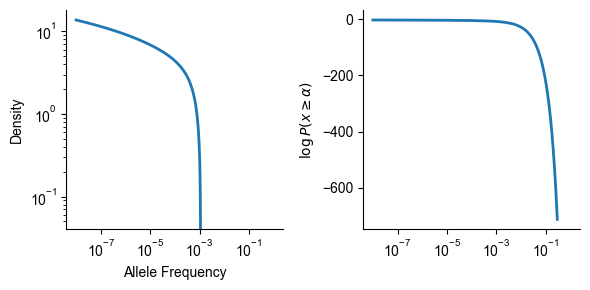

In [2]:
# Can we estimate this within the WF or Moran Models?
def wf_density(x0=None, N=1e5, r=10):
    """Beta approximation to the WF density - default for a new mutation at 1/2N"""
    assert r > 0
    assert N > 0
    if x0 is not None:
        assert x0 > 0
    else:
        x0 = 1/(2*N)
    ex_r = x0
    vx_r = x0*(1-x0)*(1 - np.exp(-r/(2*N)))
    a_xr = (ex_r*(1.0 - ex_r)/vx_r - 1)*ex_r
    b_xr = (ex_r*(1.0 - ex_r)/vx_r - 1)*(1 - ex_r)
    return beta(a=a_xr, b=b_xr)

test_beta = wf_density(r=100)
af = np.logspace(-8,0,1000)
fig, [ax0,ax1] = plt.subplots(1, 2, figsize=(6,3), layout='tight', sharex=True)
ax0.loglog(af, test_beta.logpdf(af), lw=2)
ax0.set_ylabel('Density')
ax0.set_xlabel('Allele Frequency')
debox(ax0)
ax1.plot(af, test_beta.logsf(af), lw=2)
ax1.set_ylabel(r'$\log P(x \geq \alpha)$')
debox(ax1)
plt.savefig('plots/wf_density.png', bbox_inches='tight', dpi=300)

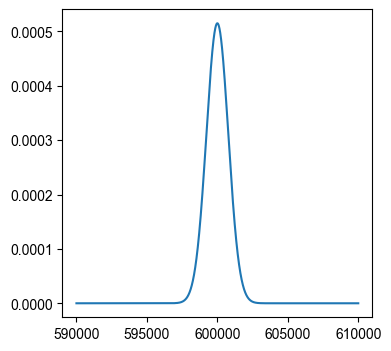

In [3]:
def new_muts(mu=1e-9, N=1e5, L=3e9):
    """Number of new mutations per generation."""
    return poisson(mu*2*N*L)

rv = new_muts()
mean_ac = rv.mean()
acs = np.arange(int(mean_ac - 10000), int(mean_ac + 10000))
fig, ax = plt.subplots(1,1,figsize=(4,4))
ax.plot(acs, rv.pmf(acs))

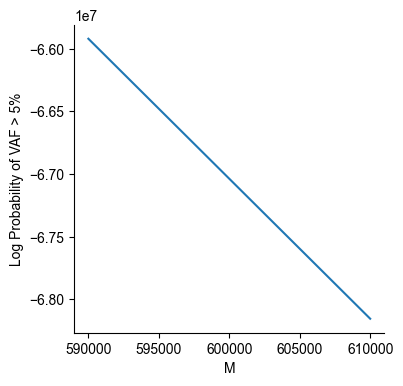

In [4]:
fig, ax = plt.subplots(1,1,figsize=(4,4))
ax.plot(acs, rv.logpmf(acs) + acs * test_beta.logsf(5e-2))
ax.set_xlabel('M')
ax.set_ylabel('Log Probability of VAF > 5%')
debox(ax)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 51.55it/s]


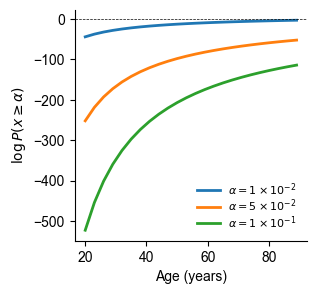

In [5]:
def evaluate_vafs(alpha=5e-2, age=50, mu=1.31e-9, N=1e5):
    """Evaluate the probability of a mutation reaching a VAF threshold due to drift alone."""
    assert alpha > 0
    assert age > 0
    assert mu > 0
    assert N > 0
    ngen = int(2*age)
    muts = new_muts(mu = mu, N=N)
    mean_ac = muts.mean()
    cur_log_prob = np.zeros(ngen)
    for i in range(ngen):
        r = ngen - i
        tb = wf_density(N=N, r=r)
        cur_log_prob[i] = np.log(mean_ac) + tb.logsf(alpha)
    # Do some cleanup later of the infs
    cur_log_prob[cur_log_prob == -np.inf] = np.nanmin(cur_log_prob[cur_log_prob != -np.inf])
    return logsumexp(cur_log_prob)

fig ,ax = plt.subplots(1,1,figsize=(3,3))
ages = np.arange(20, 90, 3)
alphas = [1e-2, 5e-2, 1e-1]
# for x in alphas:
vaf_thresh = np.array([np.nansum(evaluate_vafs(age = a, alpha=1e-2, N=1e5)) for a in tqdm(ages)])
ax.plot(ages, vaf_thresh, label=r'$\alpha = 1\times10^{-2}$', lw=2)
vaf_thresh = np.array([np.nansum(evaluate_vafs(age = a, alpha=5e-2, N=1e5)) for a in tqdm(ages)])
ax.plot(ages, vaf_thresh, label=r'$\alpha = 5\times10^{-2}$', lw=2)
vaf_thresh = np.array([np.nansum(evaluate_vafs(age = a, alpha=1e-1, N=1e5)) for a in tqdm(ages)])
ax.plot(ages, vaf_thresh, label=r'$\alpha = 1\times10^{-1}$', lw=2)
ax.axhline(0.0, linestyle='--', lw=0.5, color='black')

ax.legend(labelspacing = 0, fontsize=8, frameon=False)
debox(ax);
ax.set_ylabel(r'$\log P(x \geq \alpha)$')
ax.set_xlabel(r'Age (years)')
plt.savefig('plots/drift_mutation_likelihood.121525.png', bbox_inches='tight', dpi=300)
plt.savefig('plots/drift_mutation_likelihood.121525.pdf', bbox_inches='tight', dpi=300)

In [6]:
# Plotting with respect to the actual realized VAF estimates for TERTp
df = pl.read_excel('Table_TERTp_Age_VAF.xlsx')
df.head()

Unique Pt ID,Age at sequencing,TERTp Mutation?,TERTp VAF
str,i64,str,f64
"""523""",30,"""No""",0.0
"""531""",30,"""No""",0.0
"""392""",34,"""No""",0.0
"""526""",34,"""No""",0.0
"""539""",36,"""Yes""",30.3


Text(0, 0.5, 'TERTp VAF')

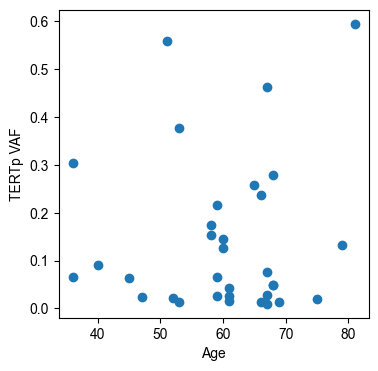

In [7]:
fig, ax = plt.subplots(1,1,figsize=(4,4))
cur_df = df.filter(pl.col('TERTp Mutation?') == "Yes")
ax.scatter(cur_df['Age at sequencing'].to_numpy(), cur_df['TERTp VAF'].to_numpy() / 100)
ax.set_xlabel('Age')
ax.set_ylabel('TERTp VAF')

In [8]:
from pymc.math import logdiffexp_numpy

def evaluate_vaf_range(a=0.1, b=0.15, age=50, mu=1.31e-9, N=1e5):
    """Evaluate the probability of a mutation reaching a VAF threshold due to drift alone."""
    assert age > 0
    assert mu > 0
    assert N > 0
    assert b > a
    assert (a > 0) and (a < 1)
    assert (b > 0) and (b < 1)
    ngen = int(2*age)
    muts = new_muts(mu = mu, N=N)
    mean_ac = muts.mean()
    cur_log_prob = np.zeros(ngen)
    for i in range(ngen):
        r = ngen - i
        tb = wf_density(N=N, r=r)
        log_p = logdiffexp_numpy(tb.logsf(a), tb.logsf(b))
        cur_log_prob[i] = np.log(mean_ac) + log_p
    # Do some cleanup later of the infs
    cur_log_prob[np.isnan(cur_log_prob)] = np.nanmin(cur_log_prob)
    
    return logsumexp(cur_log_prob)

evaluate_vaf_range(a=0.3, b=0.31, N = 1e5)

/var/folders/l9/4c849x1156qgtv52spq5t1vr0000gn/T/ipykernel_59755/2461316693.py:18: FutureWarning: pymc.math.logdiffexp_numpy is being deprecated.
  log_p = logdiffexp_numpy(tb.logsf(a), tb.logsf(b))
/Users/aabiddanda/.venv/lib/python3.12/site-packages/pymc/math.py:289: RuntimeWarning: invalid value encountered in scalar subtract
  return a + log1mexp_numpy(b - a, negative_input=True)
/Users/aabiddanda/.venv/lib/python3.12/site-packages/pymc/math.py:289: FutureWarning: pymc.math.log1mexp_numpy is being deprecated.
  return a + log1mexp_numpy(b - a, negative_input=True)
/var/folders/l9/4c849x1156qgtv52spq5t1vr0000gn/T/ipykernel_59755/2461316693.py:21: RuntimeWarning: All-NaN slice encountered
  cur_log_prob[np.isnan(cur_log_prob)] = np.nanmin(cur_log_prob)


np.float64(nan)

In [9]:
logliks = []
lower_range = []
upper_range = []
vaf_sd = []
for age, vaf in tqdm(zip(cur_df['Age at sequencing'].to_numpy(), cur_df['TERTp VAF'].to_numpy() / 100)):
    # sd_vaf = np.sqrt(vaf*(1.- vaf)) / 1000
    sd_vaf = 0.5/100
    # print(age, vaf, sd_vaf)
    cur_loglik = evaluate_vaf_range(a=vaf-sd_vaf, b=vaf+sd_vaf, age=age)
    logliks.append(cur_loglik)
    lower_range.append(vaf - sd_vaf)
    upper_range.append(vaf + sd_vaf)
    vaf_sd.append(sd_vaf)
tot_df = cur_df.with_columns(
    pl.Series(logliks).alias('LogLikelihood'), 
    pl.Series(lower_range).alias('TERTp_VAF_lower'), 
    pl.Series(upper_range).alias('TERTp_VAF_upper'), pl.Series(vaf_sd).alias('TERTp_VAF_sd')
).with_columns(
    (
        pl.col('TERTp VAF') / 100
    ).alias('TERTp_VAF')
).rename({'Age at sequencing': 'Age'})
tot_df.head()

0it [00:00, ?it/s]/var/folders/l9/4c849x1156qgtv52spq5t1vr0000gn/T/ipykernel_59755/2461316693.py:18: FutureWarning: pymc.math.logdiffexp_numpy is being deprecated.
  log_p = logdiffexp_numpy(tb.logsf(a), tb.logsf(b))
/var/folders/l9/4c849x1156qgtv52spq5t1vr0000gn/T/ipykernel_59755/2461316693.py:21: RuntimeWarning: All-NaN slice encountered
  cur_log_prob[np.isnan(cur_log_prob)] = np.nanmin(cur_log_prob)
33it [00:00, 38.54it/s]


Unique Pt ID,Age,TERTp Mutation?,TERTp VAF,LogLikelihood,TERTp_VAF_lower,TERTp_VAF_upper,TERTp_VAF_sd,TERTp_VAF
str,i64,str,f64,f64,f64,f64,f64,f64
"""539""",36,"""Yes""",30.3,NaN,0.298,0.308,0.005,0.303
"""539""",36,"""Yes""",6.6,-170.472575,0.061,0.071,0.005,0.066
"""522""",40,"""Yes""",9.0,-218.067118,0.085,0.095,0.005,0.09
"""391""",45,"""Yes""",6.32,-128.702456,0.0582,0.0682,0.005,0.0632
"""529""",47,"""Yes""",2.36,-33.539369,0.0186,0.0286,0.005,0.0236


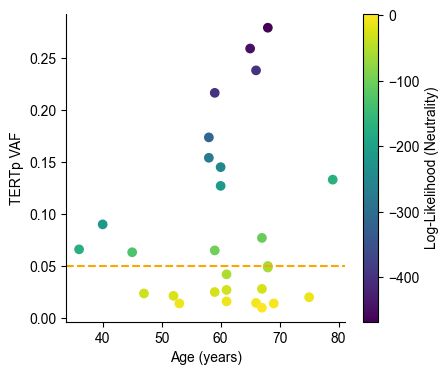

In [10]:
fig, ax = plt.subplots(1,1,figsize=(4.5,4))
im = ax.scatter(tot_df['Age'].to_numpy(), 
           tot_df['TERTp_VAF'].to_numpy(), c=tot_df['LogLikelihood'].to_numpy())
fig.colorbar(im, label='Log-Likelihood (Neutrality)')
ax.set_xlabel('Age (years)')
ax.set_ylabel('TERTp VAF')
# ax.set_yscale('log')
debox(ax);
ax.axhline(y=5e-2, color='orange', linestyle='--')
plt.savefig('plots/age_vs_TERTpVAF.121525.png', bbox_inches='tight', dpi=300)
plt.savefig('plots/age_vs_TERTpVAF.121525.pdf', bbox_inches='tight', dpi=300)

In [11]:
tot_df.sort(pl.col('LogLikelihood')).drop_nans().filter(pl.col('TERTp VAF') > 5)

Unique Pt ID,Age,TERTp Mutation?,TERTp VAF,LogLikelihood,TERTp_VAF_lower,TERTp_VAF_upper,TERTp_VAF_sd,TERTp_VAF
str,i64,str,f64,f64,f64,f64,f64,f64
"""411""",68,"""Yes""",27.9,-467.98688,0.274,0.284,0.005,0.279
"""090""",65,"""Yes""",25.9,-447.84789,0.254,0.264,0.005,0.259
"""JHH227""",59,"""Yes""",21.64,-399.407285,0.2114,0.2214,0.005,0.2164
"""301""",66,"""Yes""",23.8,-398.867807,0.233,0.243,0.005,0.238
"""543""",58,"""Yes""",17.36,-314.993759,0.1686,0.1786,0.005,0.1736
…,…,…,…,…,…,…,…,…
"""539""",36,"""Yes""",6.6,-170.472575,0.061,0.071,0.005,0.066
"""467""",79,"""Yes""",13.3,-169.450894,0.128,0.138,0.005,0.133
"""391""",45,"""Yes""",6.32,-128.702456,0.0582,0.0682,0.005,0.0632


In [12]:
tot_df.filter(pl.col('Age') == 36)

Unique Pt ID,Age,TERTp Mutation?,TERTp VAF,LogLikelihood,TERTp_VAF_lower,TERTp_VAF_upper,TERTp_VAF_sd,TERTp_VAF
str,i64,str,f64,f64,f64,f64,f64,f64
"""539""",36,"""Yes""",30.3,NaN,0.298,0.308,0.005,0.303
"""539""",36,"""Yes""",6.6,-170.472575,0.061,0.071,0.005,0.066


In [13]:
np.exp(-170.472575)

np.float64(9.219372480356622e-75)

0it [00:00, ?it/s]/var/folders/l9/4c849x1156qgtv52spq5t1vr0000gn/T/ipykernel_59755/2461316693.py:18: FutureWarning: pymc.math.logdiffexp_numpy is being deprecated.
  log_p = logdiffexp_numpy(tb.logsf(a), tb.logsf(b))
/Users/aabiddanda/.venv/lib/python3.12/site-packages/pymc/math.py:289: FutureWarning: pymc.math.log1mexp_numpy is being deprecated.
  return a + log1mexp_numpy(b - a, negative_input=True)
/Users/aabiddanda/.venv/lib/python3.12/site-packages/pymc/math.py:289: RuntimeWarning: invalid value encountered in scalar subtract
  return a + log1mexp_numpy(b - a, negative_input=True)
3it [00:00, 36.88it/s]


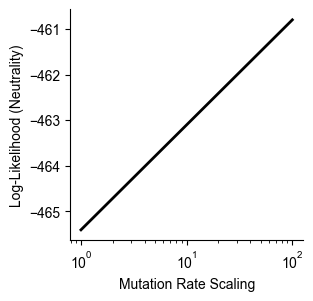

In [14]:
logliks = []
lower_range = []
upper_range = []
vaf_sd = []
xs = []
for age, vaf, x in tqdm(zip([60, 60, 60], [0.25,0.25, 0.25], [1, 10, 100])):
    # sd_vaf = np.sqrt(vaf*(1.- vaf)) / 1000
    sd_vaf = 0.5/100
    # print(age, vaf, sd_vaf)
    cur_loglik = evaluate_vaf_range(a=vaf-sd_vaf, b=vaf+sd_vaf, age=age, mu=1.31e-9*x)
    logliks.append(cur_loglik)
    lower_range.append(vaf - sd_vaf)
    upper_range.append(vaf + sd_vaf)
    vaf_sd.append(sd_vaf)
    xs.append(x)

fig, ax = plt.subplots(1,1,figsize=(3,3))
ax.plot(xs, logliks, lw=2, color='black')
ax.set_xscale('log')
ax.set_ylabel('Log-Likelihood (Neutrality)')
ax.set_xlabel('Mutation Rate Scaling')
debox(ax)
plt.savefig('plots/mutation_rate_modifier.011626.png', bbox_inches='tight', dpi=300)
plt.savefig('plots/mutation_rate_modifier.011626.pdf', bbox_inches='tight', dpi=300)